--- Initial Data Inspection ---
First 5 rows of the dataset:
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65  Female              0.7               0.1                   187   
1   62    Male             10.9               5.5                   699   
2   62    Male              7.3               4.1                   490   
3   58    Male              1.0               0.4                   182   
4   72    Male              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Rati

C:\Users\Roshani\AppData\Local\Temp\ipykernel_10892\825738651.py:35: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Albumin_and_Globulin_Ratio'].fillna(median_ag_ratio, inplace=True)


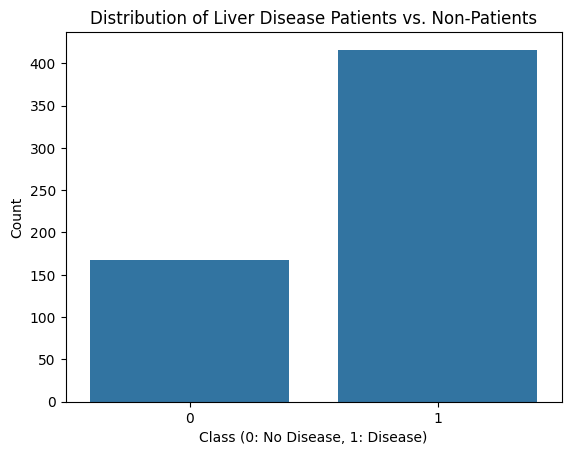

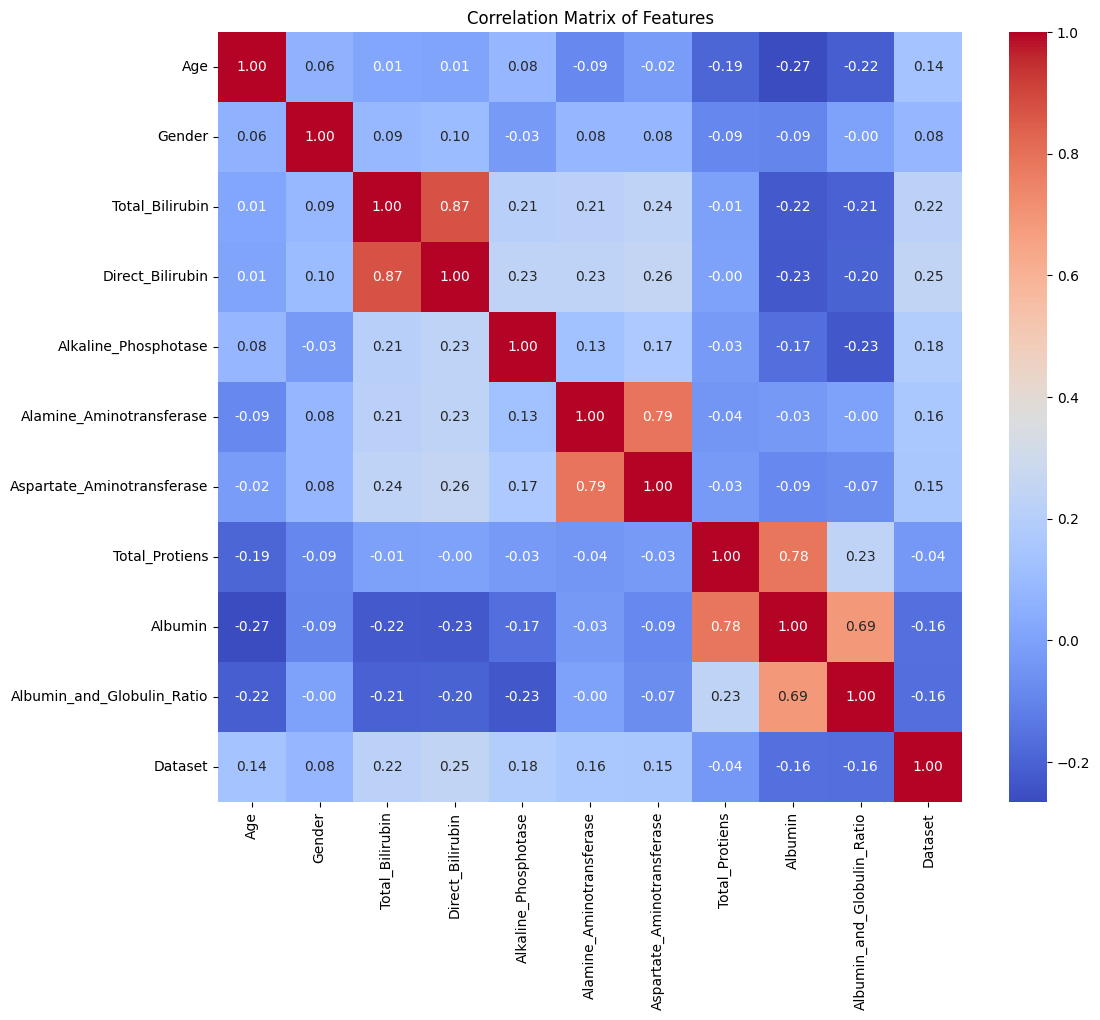


--- Logistic Regression Model ---

--- Random Forest Model ---

Logistic Regression Performance:
Accuracy: 0.7350
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.18      0.28        34
           1       0.74      0.96      0.84        83

    accuracy                           0.74       117
   macro avg       0.70      0.57      0.56       117
weighted avg       0.72      0.74      0.68       117

Confusion Matrix:
 [[ 6 28]
 [ 3 80]]

Random Forest Performance:
Accuracy: 0.7350
Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.32      0.42        34
           1       0.77      0.90      0.83        83

    accuracy                           0.74       117
   macro avg       0.67      0.61      0.62       117
weighted avg       0.71      0.74      0.71       117

Confusion Matrix:
 [[11 23]
 [ 8 75]]

--- Predicting on New Sample Data ---
For sample_patient_data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00225/Indian%20Liver%20Patient%20Dataset%20(ILPD).csv"

columns = [
    "Age", "Gender", "Total_Bilirubin", "Direct_Bilirubin",
    "Alkaline_Phosphotase", "Alamine_Aminotransferase",
    "Aspartate_Aminotransferase", "Total_Protiens", "Albumin",
    "Albumin_and_Globulin_Ratio", "Dataset"
]
df = pd.read_csv(url, header=None, names=columns)

print("--- Initial Data Inspection ---")
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataset Information:")
df.info()
print("\nDescriptive Statistics:")
print(df.describe())


print("\n--- Data Preprocessing ---")
print("Missing values before handling:")
print(df.isnull().sum())

median_ag_ratio = df['Albumin_and_Globulin_Ratio'].median()
df['Albumin_and_Globulin_Ratio'].fillna(median_ag_ratio, inplace=True)

print("\nMissing values after handling:")
print(df.isnull().sum())

le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

df['Dataset'] = df['Dataset'].map({1: 1, 2: 0})
print("\nTarget variable 'Dataset' distribution (1: Patient, 0: No Patient):")
print(df['Dataset'].value_counts())

sns.countplot(x='Dataset', data=df)
plt.title('Distribution of Liver Disease Patients vs. Non-Patients')
plt.xlabel('Class (0: No Disease, 1: Disease)')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Features')
plt.show()

X = df.drop('Dataset', axis=1)
y = df['Dataset']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n--- Logistic Regression Model ---")
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

print("\n--- Random Forest Model ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
print("\nLogistic Regression Performance:")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}")
print("Classification Report:\n", classification_report(y_test, lr_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_pred))

rf_pred = rf_model.predict(X_test_scaled)
print("\nRandom Forest Performance:")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print("Classification Report:\n", classification_report(y_test, rf_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))

def predict_liver_disease(new_data, model, scaler, label_encoder):
    
    new_df = pd.DataFrame([new_data])

    new_df['Gender'] = label_encoder.transform(new_df['Gender'])

    new_df_scaled = scaler.transform(new_df)

    prediction = model.predict(new_df_scaled)
    prediction_proba = model.predict_proba(new_df_scaled)

    if prediction[0] == 1:
        return f"Prediction: LIVER DISEASE. Confidence: {prediction_proba[0][1]*100:.2f}%"
    else:
        return f"Prediction: NO LIVER DISEASE. Confidence: {prediction_proba[0][0]*100:.2f}%"

sample_patient_data_disease = {
    "Age": 65,
    "Gender": "Male",
    "Total_Bilirubin": 0.7,
    "Direct_Bilirubin": 0.1,
    "Alkaline_Phosphotase": 187,
    "Alamine_Aminotransferase": 16,
    "Aspartate_Aminotransferase": 18,
    "Total_Protiens": 6.8,
    "Albumin": 3.3,
    "Albumin_and_Globulin_Ratio": 0.90
}

sample_patient_data_healthy = {
    "Age": 32,
    "Gender": "Female",
    "Total_Bilirubin": 0.9,
    "Direct_Bilirubin": 0.2,
    "Alkaline_Phosphotase": 150,
    "Alamine_Aminotransferase": 25,
    "Aspartate_Aminotransferase": 30,
    "Total_Protiens": 7.2,
    "Albumin": 4.1,
    "Albumin_and_Globulin_Ratio": 1.2
}


print("\n--- Predicting on New Sample Data ---")
prediction1 = predict_liver_disease(sample_patient_data_disease, rf_model, scaler, le)
print(f"For sample_patient_data_disease: {prediction1}")
prediction2 = predict_liver_disease(sample_patient_data_healthy, rf_model, scaler, le)
print(f"For sample_patient_data_healthy: {prediction2}")